In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
df = pd.read_parquet(
    "../data/customer_orders_2024-01_2026-08.parquet"
)

In [69]:
df.shape

(967415, 16)

In [68]:
df_clean = df.copy()

df_clean["line_revenue"] = (
    df_clean["quantity"] * df_clean["new_price"]
)

print("Provisional revenue:",
      round(df_clean["line_revenue"].sum(), 2))

Provisional revenue: 2746061.3


1. new_price represents the price per unit rather than the total line price?
2. refunds, cancellations or other adjustments are included in the dataset?
3. recorded prices match the amounts customers actually paid?

## Step 1: RFM Calculation ##

### Recency, Frequency, Monetary (RFM) Analysis ###
| Metric | Definition | Calculation |
| --- | --- | --- |
| Recency | How recently a customer purchased | Days since last order |
| Frequency | How often a customer purchased | Number of unique orders |
| Monetary | How much a customer spent | Sum of line avenue |

### Recency ###
Recency = Reference Date - Last Purchase Date

In [72]:
# Reference date: one day after the last order
reference_date = (
    df_clean["order_datetime"].max()
    + pd.Timedelta(days=1)
)

reference_date

Timestamp('2026-09-01 22:55:28')

In [85]:
# Aggregate transactions to customer level
rfm = df_clean.groupby("user_id").agg(
    last_purchase=("order_datetime", "max"),
    frequency=("order_id", "nunique"),
    monetary=("line_revenue", "sum")
)

rfm.reset_index()

,user_id,last_purchase,frequency,monetary
0,0DKWGcJ8itd0AxqSldV9lI6p74l2,2026-08-31 05:49:49,198,3705.6
1,0DqeDKgxqzWNRGBys2FdA0FGmbs2,2026-01-30 19:19:24,93,2052.1
2,0R9p4rL8nthxpaVa3LDlpeXNnrE3,2026-08-14 14:03:31,100,5182.8
3,0S023rB22zYRt1k1vbr5mkbJesW2,2026-08-31 19:14:13,146,6464.4
4,0Wys4DCHzwVaFYSCnuMqo347XY82,2025-12-08 23:15:29,1,41.5
...,...,...,...,...
995,zpH3BaUQidQeioD3YGIfXS4g55q1,2026-08-28 14:13:25,107,1419.7
996,zrpth5g2OIfLiKpUqwshs5Q8gLi2,2026-08-28 13:04:34,334,6519.5
997,zt6tudZOACVbqFGXtexsnMZzS8J2,2026-08-28 09:19:38,174,9842.2
998,zzUnL94WcyXs0m8beqk94swBM0v2,2026-08-29 10:55:50,144,5231.8


In [86]:
# Calculate recency in days
rfm["recency"] = (
    reference_date - rfm["last_purchase"]
).dt.days

rfm["recency"]

user_id
0DKWGcJ8itd0AxqSldV9lI6p74l2      1
0DqeDKgxqzWNRGBys2FdA0FGmbs2    214
0R9p4rL8nthxpaVa3LDlpeXNnrE3     18
0S023rB22zYRt1k1vbr5mkbJesW2      1
0Wys4DCHzwVaFYSCnuMqo347XY82    266
                               ... 
zpH3BaUQidQeioD3YGIfXS4g55q1      4
zrpth5g2OIfLiKpUqwshs5Q8gLi2      4
zt6tudZOACVbqFGXtexsnMZzS8J2      4
zzUnL94WcyXs0m8beqk94swBM0v2      3
zzvxJhvEtMT2Qrh9QVOe66zQy8j1     12
Name: recency, Length: 1000, dtype: int64

In [87]:
# Arrange columns
rfm = rfm[
    ["recency", "frequency", "monetary"]
]

len(rfm)

1000

In [88]:
rfm.describe().round(2)

,recency,frequency,monetary
count,1000.00,1000.00,1000.00
mean,62.04,141.15,2746.06
std,128.34,124.74,2380.15
min,1.00,1.00,4.00
25%,3.00,77.00,1024.93
50%,6.00,119.50,2199.70
75%,42.00,181.25,3939.80
max,625.00,1053.00,17054.10


| Recency	| Frequency | Monetary |
| --- | --- | --- |
| 6 days | 119.5 orders | €2,199.70 |
| 625 days	 | 1,053 orders | €17,054.10 |
| Some customers haven't purchased for a long time | Some customers purchase exceptionally frequently | Spending differs substantially between customers |


1. Many customers purchased recently. The median recency is only 6 days, while the average is 62 days. This large difference suggests a strongly right-skewed distribution, with some long-inactive customers.

2. Customer purchasing frequency varies significantly. The maximum is 1,053 orders, compared with a median of 119.5. These high-frequency customers may form a distinct segment.

3. Customer spending is also uneven. The maximum provisional spending is €17,054.10, substantially higher than the median of €2,199.70.

## Step 2: RFM Exploratory Data Analysis ##

### Skewness Analysis ###

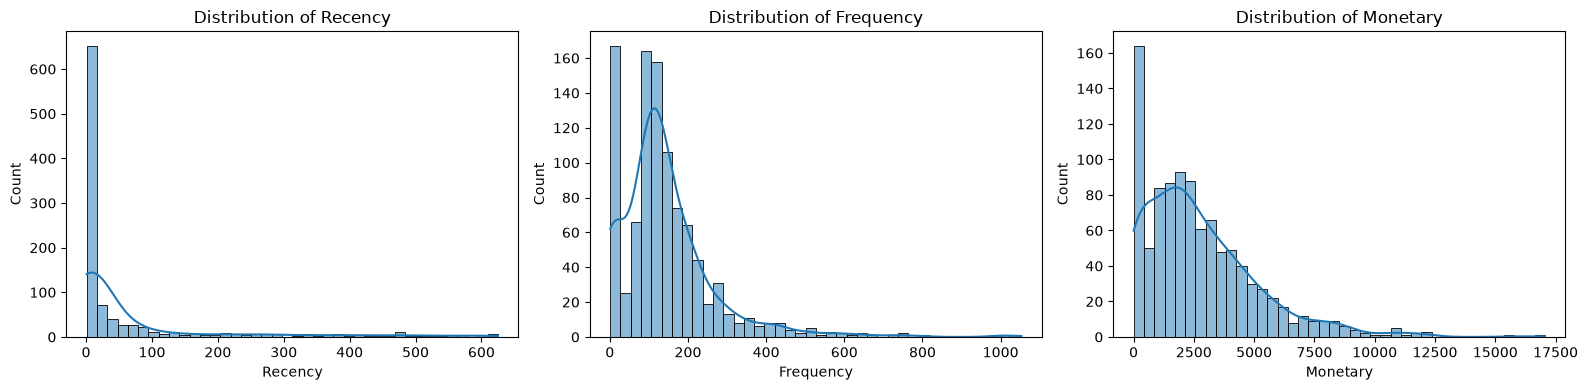

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = ["recency", "frequency", "monetary"]

for i, metric in enumerate(metrics):
    sns.histplot(
        rfm[metric],
        bins=40,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {metric.capitalize()}"
    )
    axes[i].set_xlabel(metric.capitalize())

plt.tight_layout()
plt.show()

In [82]:
rfm[
    ["recency", "frequency", "monetary"]
].skew().round(2)

recency      2.68
frequency    2.43
monetary     1.46
dtype: float64

| Recency	| Frequency | Monetary |
| --- | --- | --- |
| 2.68 | 2.43 | 1.46 |
| Strong positive skew	 | Strong positive skew | Moderate positive skew |

Recency: Most customers purchased recently, but some have been inactive for hundreds of days.\
Frequency: Most customers have moderate or low order counts, while a smaller group orders very frequently.\
Monetary: Most customers have lower total spending, while a smaller group contributes substantially more revenue.

### Correlation Analysis ###

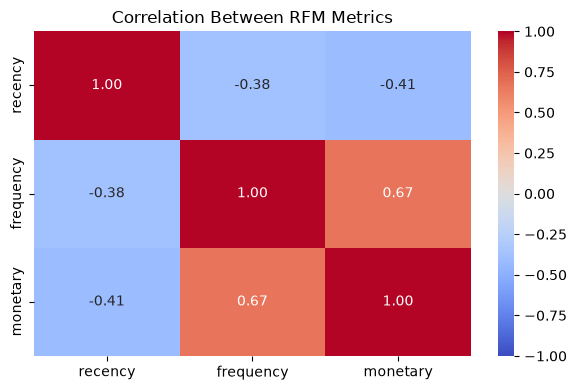

,recency,frequency,monetary
recency,1.00,-0.38,-0.41
frequency,-0.38,1.00,0.67
monetary,-0.41,0.67,1.00


In [84]:
correlation = rfm[
    ["recency", "frequency", "monetary"]
].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between RFM Metrics")
plt.tight_layout()
plt.show()

correlation.round(2)

Positive Correlation: As X increases, Y tends to increase.\
Negative Correlation: As X increases, Y tends to decrease.

frequency vs monetary (+0.67): frequency increase, monetary increase (place more order, spend more) \
frequency vs recency (-0.38): frequency increase, recency decrease (last visit closer) \
recency vs monetary (-0.41): recency increase, monetary decrease (last visit further, spend lesser)

Histogram showing that the RFM variables are not normally distributed.
So, apply log transformation followed by standardisarion before applying clustering model to reduce skewness, and places the features on comparable scales.

## Step 3: Log Transformation and Scaling ##

Log Transformation used to reduce positive skewness (right skewness)\
Log transformation compressed larger values more strongly than smaller values\
To reduce the influence of extreme RFM values and improve the usefulness of customer segmentation.

np.log1p() which calculates log(1+x)

Log transformation changes the shape of a distribution and compresses large values. \
StandardScaler changes the mean to 0 and standard deviation to 1, but does not remove skewness.

In [91]:
# Apply log transformation to RFM metrics
rfm_log = np.log1p(
    rfm[["recency", "frequency", "monetary"]]
)

rfm_log

,recency,frequency,monetary
user_id,,,
0DKWGcJ8itd0AxqSldV9lI6p74l2,0.693147,5.293305,8.217870
0DqeDKgxqzWNRGBys2FdA0FGmbs2,5.370638,4.543295,7.627106
0R9p4rL8nthxpaVa3LDlpeXNnrE3,2.944439,4.615121,8.553294
0S023rB22zYRt1k1vbr5mkbJesW2,0.693147,4.990433,8.774220
0Wys4DCHzwVaFYSCnuMqo347XY82,5.587249,0.693147,3.749504
...,...,...,...
zpH3BaUQidQeioD3YGIfXS4g55q1,1.609438,4.682131,7.258905
zrpth5g2OIfLiKpUqwshs5Q8gLi2,1.609438,5.814131,8.782706
zt6tudZOACVbqFGXtexsnMZzS8J2,1.609438,5.164786,9.194536


In [94]:
print("Skewness before transformation:")
print(rfm.skew().round(2))

print("\nSkewness after transformation:")
print(rfm_log.skew().round(2))

Skewness before transformation:
recency      2.68
frequency    2.43
monetary     1.46
dtype: float64

Skewness after transformation:
recency      0.78
frequency   -1.46
monetary    -1.58
dtype: float64


+0.78 Substantially improved \
-1.46 Left-skewed (overcorrect original skewness) \
-1.58 Left-skewed (overcorrect original skewness) 

Recency: The log transformation successfully reduced the strong positive skewness. Customers with very high recency values no longer dominate the numerical scale as much.

Frequency: Most customers are now concentrated toward higher transformed values, with a tail extending toward lower values. Check histogram.

Monetary: Similarly, most customers are concentrated around higher log-spending values, with a smaller group of low-spending customers forming the left tail.

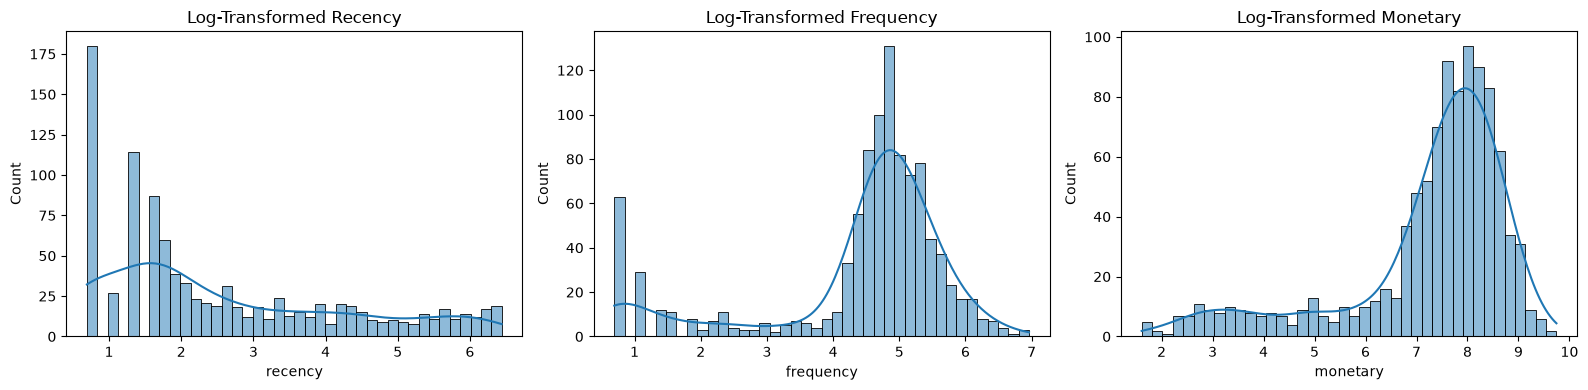

In [95]:
# Histogram after applying log transformation
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, metric in enumerate(rfm_log.columns):
    sns.histplot(
        rfm_log[metric],
        bins=40,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Log-Transformed {metric.capitalize()}"
    )

plt.tight_layout()
plt.show()

Log transformation improved recency's skewness but reversed the skewness of frequency and monetary.

Apply scaling to avoid Monetary from dominating Euclidean distances because its numerical range is much larger

In [96]:
# standardise transform data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=rfm_log.columns,
    index=rfm_log.index
)

print("Scaled feature means:")
print(rfm_scaled_df.mean().round(2))

print("\nScaled feature standard deviations:")
print(rfm_scaled_df.std(ddof=0).round(2))

Scaled feature means:
recency      0.0
frequency   -0.0
monetary     0.0
dtype: float64

Scaled feature standard deviations:
recency      1.0
frequency    1.0
monetary     1.0
dtype: float64


## Step 4: Evaluate Cluster Counts ##

### Calculate Elbow and Silhouette Scores ###

- Inertia (Elbow Method): Measures how tightly customers are grouped around their cluster centres. Lower is better, but inertia naturally decreases as the number of clusters increases. Where does increasing the number of clusters stop providing substantial improvement?
- Silhouette Score: Measures how well customers fit within their assigned clusters compared with other clusters. Higher is generally better. Which cluster counts produce well-separated customer groups?

In [97]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertias.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

results = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})

results.round(3)

,k,inertia,silhouette_score
0,2,1053.727,0.653
1,3,624.834,0.496
2,4,520.658,0.472
3,5,427.518,0.322
4,6,373.360,0.298
5,7,332.840,0.298
6,8,300.406,0.303
7,9,271.801,0.297
8,10,251.483,0.297


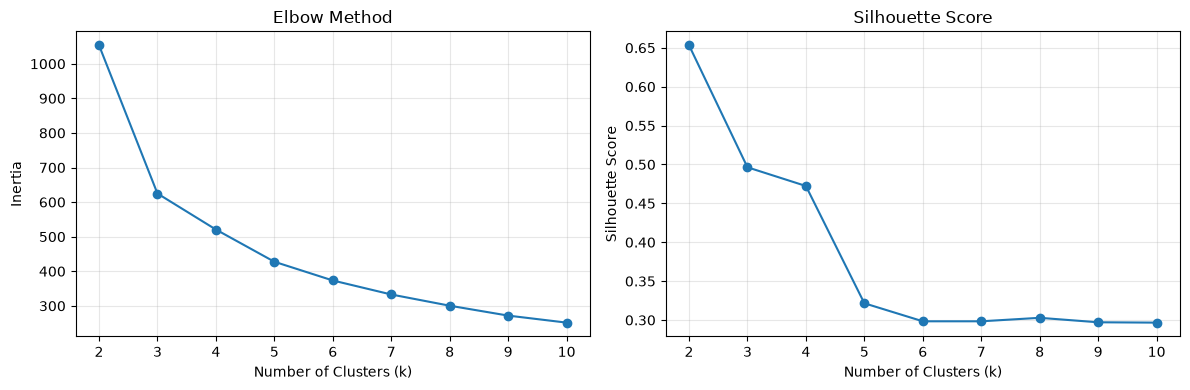

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow Method
axes[0].plot(
    results["k"],
    results["inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

# Silhouette Score
axes[1].plot(
    results["k"],
    results["silhouette_score"],
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 5: Profile and Interpret Clusters ##

### Fit 3 candidate models ###

In [99]:
from sklearn.cluster import KMeans

# Create a copy to avoid modifying original RFM data
rfm_comparison = rfm.copy()

for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    rfm_comparison[f"cluster_{k}"] = (
        model.fit_predict(rfm_scaled)
    )

### Compare Cluster Size ###

In [100]:
for k in [2, 3, 4]:
    print(f"\nCluster sizes for k = {k}")

    print(
        rfm_comparison[f"cluster_{k}"]
        .value_counts()
        .sort_index()
    )


Cluster sizes for k = 2
cluster_2
0    827
1    173
Name: count, dtype: int64

Cluster sizes for k = 3
cluster_3
0    229
1    629
2    142
Name: count, dtype: int64

Cluster sizes for k = 4
cluster_4
0    223
1    610
2     99
3     68
Name: count, dtype: int64


### Compare RFM profiles ###

In [101]:
for k in [2, 3, 4]:
    print(f"\nRFM profiles for k = {k}")

    profile = (
        rfm_comparison
        .groupby(f"cluster_{k}")
        [["recency", "frequency", "monetary"]]
        .median()
        .round(2)
    )

    print(profile)


RFM profiles for k = 2
           recency  frequency  monetary
cluster_2                              
0              5.0      134.0    2734.5
1            223.0        2.0      61.4

RFM profiles for k = 3
           recency  frequency  monetary
cluster_3                              
0             49.0       91.0   1337.10
1              3.0      147.0   3211.00
2            239.5        2.0     38.35

RFM profiles for k = 4
           recency  frequency  monetary
cluster_4                              
0             47.0       96.0   1537.80
1              3.0      151.0   3225.95
2            351.0        1.0     26.40
3             42.5        8.0    206.45


Use median because RFM metrics contain extreme values and skewed distribution.
Choose k3 because k2 is too general, customer who purchased 3 days ago and customer who purchased 49 days ago may end up in the same broad group. (One might be very active, while the other was not purchased as recently which is very extreme.)

## Step 6: Business Recommendations and Validations ##

### Assign Cluster Labels ###

In [121]:
# Use the existing k=3 clustering results
rfm_final = rfm_comparison[
    ["recency", "frequency", "monetary", "cluster_3"]
].copy()

rfm_final = rfm_final.rename(
    columns={"cluster_3": "cluster"}
)

# Descriptive labels based on observed medians
segment_names = {
    0: "Less-Recent Moderate-Value",
    1: "Active High-Value",
    2: "Long-Inactive Low-Value"
}

rfm_final["segment"] = (
    rfm_final["cluster"].map(segment_names)
)

rfm_final["segment"].value_counts()

segment
Active High-Value             629
Less-Recent Moderate-Value    229
Long-Inactive Low-Value       142
Name: count, dtype: int64

### Calculate segment profiles ###

In [103]:
segment_profile = (
    rfm_final.groupby("segment")
    .agg(
        customers=("recency", "size"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        total_monetary=("monetary", "sum")
    )
)

segment_profile["customer_pct"] = (
    segment_profile["customers"]
    / len(rfm_final) * 100
)

segment_profile["revenue_pct"] = (
    segment_profile["total_monetary"]
    / rfm_final["monetary"].sum() * 100
)

segment_profile.round(2)

,customers,median_recency,median_frequency,median_monetary,total_monetary,customer_pct,revenue_pct
segment,,,,,,,
Active High-Value,629,3.0,147.0,3211.00,2340430.2,62.9,85.23
Less-Recent Moderate-Value,229,49.0,91.0,1337.10,395162.3,22.9,14.39
Long-Inactive Low-Value,142,239.5,2.0,38.35,10468.8,14.2,0.38


| Active High-Value Customers | Less-Recent Moderate-Value Customers | Long-Inactive Low-Value Customers |
| --- | --- | --- |
| Prioritise retention, personalised product recommendations and relevant loyalty offers. | Test re-engagement campaigns, such as personalised reminders based on previously purchased products. | Test inexpensive win-back campaigns rather than immediately allocating large promotional budgets.

revenue is concentrated among customers who are relatively recent, frequent and high-spending purchasers.

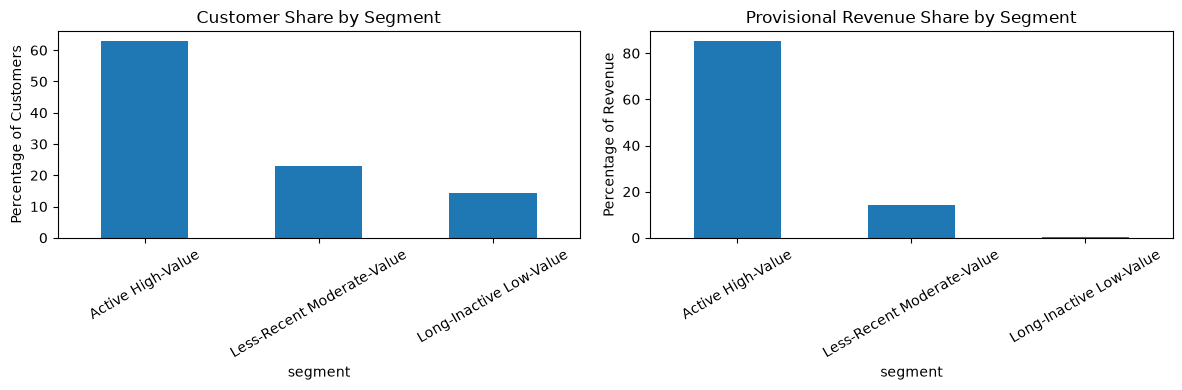

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

segment_profile["customer_pct"].plot(
    kind="bar",
    ax=axes[0],
    title="Customer Share by Segment"
)

axes[0].set_ylabel("Percentage of Customers")

segment_profile["revenue_pct"].plot(
    kind="bar",
    ax=axes[1],
    title="Provisional Revenue Share by Segment"
)

axes[1].set_ylabel("Percentage of Revenue")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Step 7: Validate the clustering model ##

### Test clustering ability ###
Using Adjusted Rand Index (ARI) to compare clustering assignments.

In [135]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np

# Fit K-Means with different random seeds
seeds = [0, 10, 20, 30, 42]

cluster_results = []

for seed in seeds:
    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=20
    )

    labels = model.fit_predict(rfm_scaled)
    cluster_results.append(labels)

# Compare each solution against the first
ari_scores = []

for labels in cluster_results[1:]:
    score = adjusted_rand_score(
        cluster_results[0],
        labels
    )
    ari_scores.append(score)

print("ARI scores:", np.round(ari_scores, 3))
print("Mean ARI:", round(np.mean(ari_scores), 3))

ARI scores: [1.    0.997 0.99  1.   ]
Mean ARI: 0.997


In [136]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np

# Fit K-Means with different random seeds
seeds = [0, 10, 20, 30, 42]

cluster_results = []

for seed in seeds:
    model = KMeans(
        n_clusters=4,
        random_state=seed,
        n_init=20
    )

    labels = model.fit_predict(rfm_scaled)
    cluster_results.append(labels)

# Compare each solution against the first
ari_scores = []

for labels in cluster_results[1:]:
    score = adjusted_rand_score(
        cluster_results[0],
        labels
    )
    ari_scores.append(score)

print("ARI scores:", np.round(ari_scores, 3))
print("Mean ARI:", round(np.mean(ari_scores), 3))

ARI scores: [1. 1. 1. 1.]
Mean ARI: 1.0


In [137]:
for k in [3, 4]:
    print(f"\nRFM profiles for K = {k}")

    profile = (
        rfm_comparison
        .groupby(f"cluster_{k}")
        [["recency", "frequency", "monetary"]]
        .median()
        .round(2)
    )

    print(profile)


RFM profiles for K = 3
           recency  frequency  monetary
cluster_3                              
0             49.0       91.0   1337.10
1              3.0      147.0   3211.00
2            239.5        2.0     38.35

RFM profiles for K = 4
           recency  frequency  monetary
cluster_4                              
0             47.0       96.0   1537.80
1              3.0      151.0   3225.95
2            351.0        1.0     26.40
3             42.5        8.0    206.45


In [138]:
import pandas as pd

# Compare cluster membership between K=3 and K=4
pd.crosstab(
    rfm_comparison["cluster_3"],
    rfm_comparison["cluster_4"],
    margins=True
)

cluster_4,0,1,2,3,All
cluster_3,,,,,
0,209,0,0,20,229
1,14,610,0,5,629
2,0,0,99,43,142
All,223,610,99,68,1000


In [139]:
for k in [3, 4]:
    summary = (
        rfm_comparison
        .groupby(f"cluster_{k}")
        .agg(
            customers=("monetary", "size"),
            total_revenue=("monetary", "sum")
        )
    )

    summary["customer_pct"] = (
        summary["customers"] / summary["customers"].sum() * 100
    )

    summary["revenue_pct"] = (
        summary["total_revenue"] / summary["total_revenue"].sum() * 100
    )

    print(f"\nK = {k}")
    display(summary.round(2))


K = 3


,customers,total_revenue,customer_pct,revenue_pct
cluster_3,,,,
0,229,395162.3,22.9,14.39
1,629,2340430.2,62.9,85.23
2,142,10468.8,14.2,0.38



K = 4


,customers,total_revenue,customer_pct,revenue_pct
cluster_4,,,,
0,223,433004.9,22.3,15.77
1,610,2291975.7,61.0,83.46
2,99,3944.7,9.9,0.14
3,68,17136.0,6.8,0.62


model produces consistent assignments under different random initialisations, using the same data and feature transformation.

### Check within-cluster variation ###

In [126]:
cluster_variation = (
    rfm_final.groupby("segment")
    [["recency", "frequency", "monetary"]]
    .agg(["median", "mean", "std"])
)

cluster_variation.round(2)

recency                 frequency                  \
                            median    mean     std    median    mean     std   
segment                                                                        
Active High-Value              3.0    4.46    3.88     147.0  187.76  127.23   
Less-Recent Moderate-Value    49.0   94.19  107.26      91.0   98.80   62.54   
Long-Inactive Low-Value      239.5  265.20  199.97       2.0    3.01    3.00   

                           monetary                    
                             median     mean      std  
segment                                                
Active High-Value           3211.00  3720.87  2329.24  
Less-Recent Moderate-Value  1337.10  1725.60  1326.49  
Long-Inactive Low-Value       38.35    73.72    78.81

Active High-Value: Customers are consistently recent purchasers, although frequency and spending vary considerably. This segment includes some exceptionally frequent buyers.

Less-Recent Moderate-Value: This group has substantial variation in recency. Its median is 49 days, but its mean is 94.19 days, suggesting some customers have been inactive much longer than others.

Long-Inactive Low-Value: Customers generally have very low purchasing frequency, but their inactivity periods vary substantially.

### Compare segmentation against existing customer status ###
To compare with the column `regular_client`

In [128]:
# Each customer has a consistent regular_client status
customer_status = (
    df.groupby("user_id")["regular_client"]
    .first()
)

# Join status with segmentation
segment_status = rfm_final.join(
    customer_status,
    how="left"
)

# Compare distributions
status_comparison = pd.crosstab(
    segment_status["segment"],
    segment_status["regular_client"],
    normalize="index"
) * 100

print("Regular vs non-regular customers by segment (%):")
status_comparison.round(2)

Regular vs non-regular customers by segment (%):


regular_client,False,True
segment,,
Active High-Value,2.86,97.14
Less-Recent Moderate-Value,17.47,82.53
Long-Inactive Low-Value,100.00,0.00


In [108]:
final_summary = (
    rfm_final.groupby("segment")
    .agg(
        customers=("recency", "size"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        total_monetary=("monetary", "sum")
    )
    .round(2)
)

final_summary["customer_share_pct"] = (
    final_summary["customers"]
    / final_summary["customers"].sum() * 100
).round(2)

final_summary["revenue_share_pct"] = (
    final_summary["total_monetary"]
    / final_summary["total_monetary"].sum() * 100
).round(2)

display(final_summary)

,customers,median_recency,median_frequency,median_monetary,total_monetary,customer_share_pct,revenue_share_pct
segment,,,,,,,
Active High-Value,629,3.0,147.0,3211.00,2340430.2,62.9,85.23
Less-Recent Moderate-Value,229,49.0,91.0,1337.10,395162.3,22.9,14.39
Long-Inactive Low-Value,142,239.5,2.0,38.35,10468.8,14.2,0.38


In [109]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

final_summary.to_csv(
    output_dir / "customer_segment_summary.csv"
)

print("Aggregated segment summary saved locally.")

Aggregated segment summary saved locally.


## Step 8: Visualization ##

### Visualize RFM profiles by segment ###
Compare median RFM values

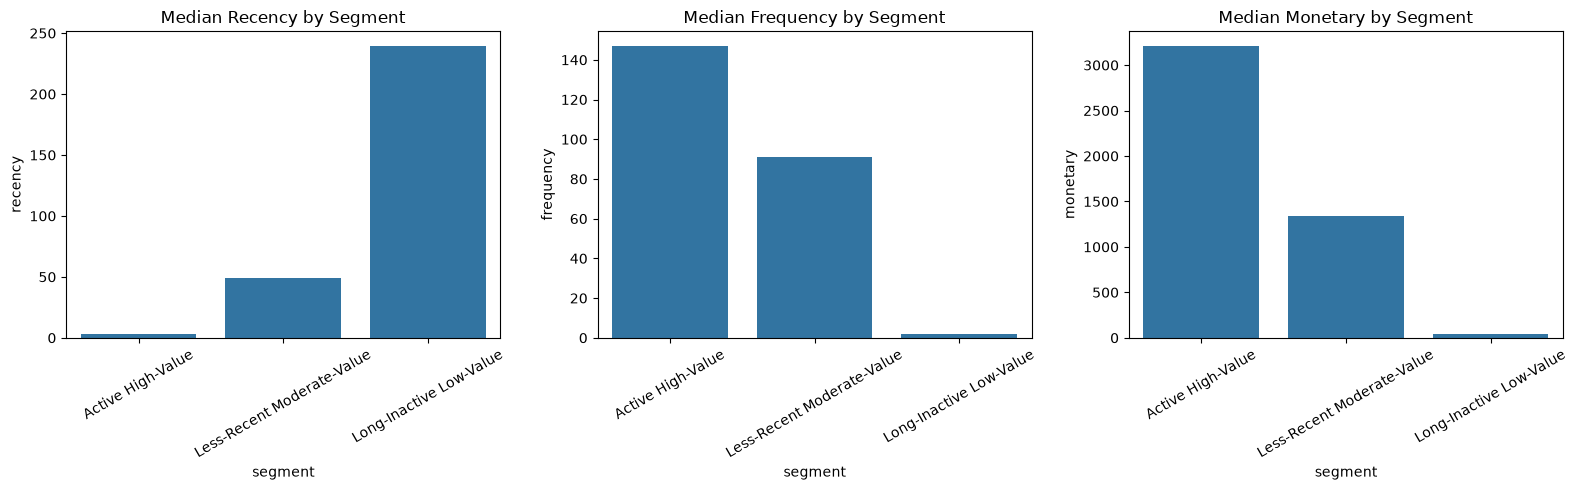

In [110]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["recency", "frequency", "monetary"]

for i, metric in enumerate(metrics):
    sns.barplot(
        data=rfm_final,
        x="segment",
        y=metric,
        estimator=np.median,
        errorbar=None,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Median {metric.capitalize()} by Segment"
    )

    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Visualise Customer Clusters ###
Frequency versus Monetary

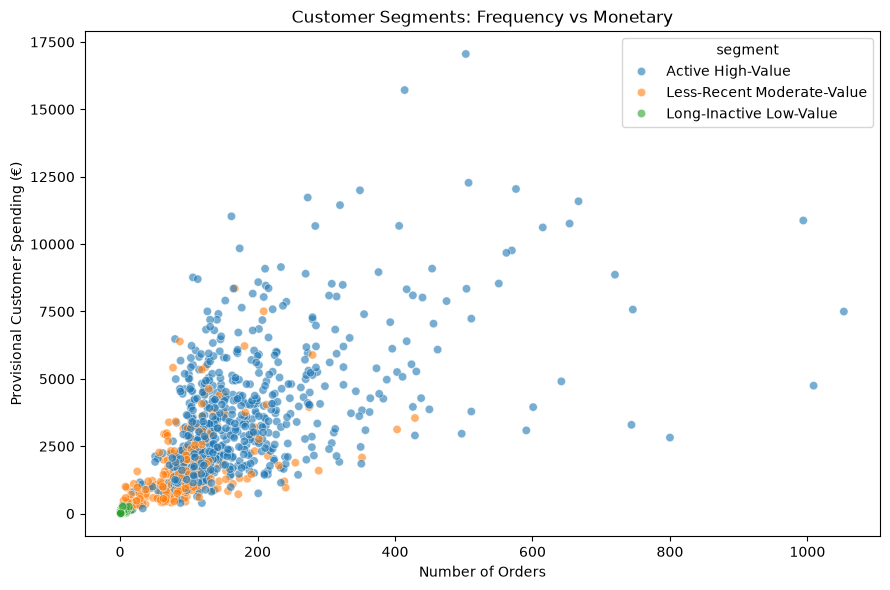

In [111]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm_final,
    x="frequency",
    y="monetary",
    hue="segment",
    alpha=0.6
)

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Number of Orders")
plt.ylabel("Provisional Customer Spending (€)")
plt.tight_layout()
plt.show()

Recency versus Frequency

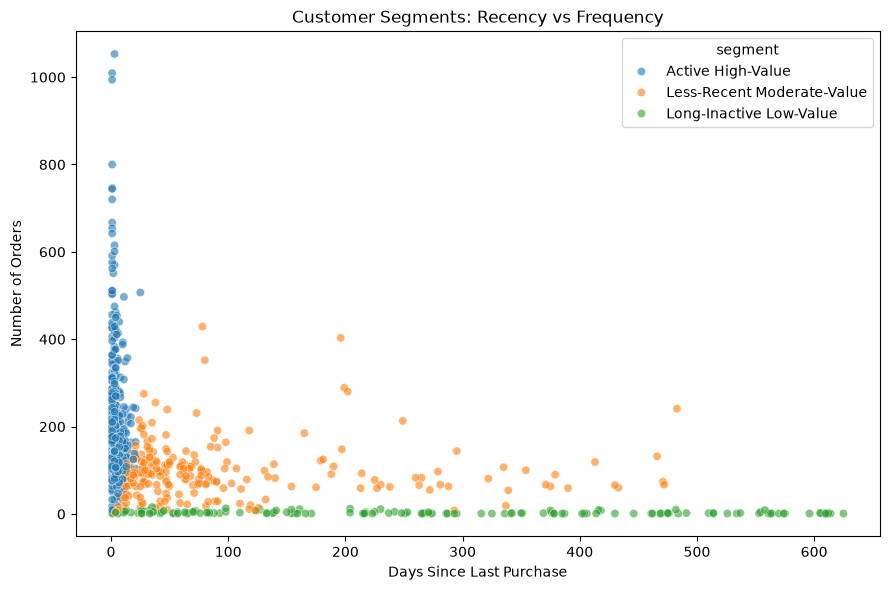

In [112]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm_final,
    x="recency",
    y="frequency",
    hue="segment",
    alpha=0.6
)

plt.title("Customer Segments: Recency vs Frequency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

### Step 9: Final Segment Comparison ###

Heatmap of segment characteristics

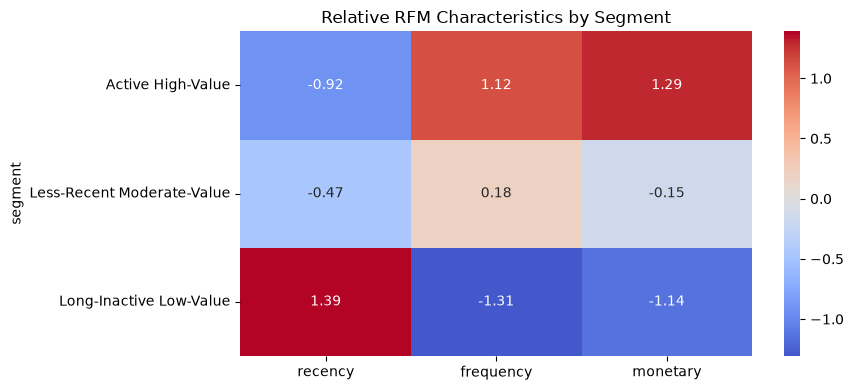

In [113]:
# Calculate median RFM metrics by segment
segment_medians = (
    rfm_final.groupby("segment")
    [["recency", "frequency", "monetary"]]
    .median()
)

# Standardise the segment medians for visualisation
segment_scaled = (
    segment_medians - segment_medians.mean()
) / segment_medians.std(ddof=0)

plt.figure(figsize=(9, 4))

sns.heatmap(
    segment_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Relative RFM Characteristics by Segment")
plt.tight_layout()
plt.show()

Positive Correlation: As X increases, Y tends to increase. \
Negative Correlation: As X increases, Y tends to decrease.